# Generate a nonlinear process dataset with Salesforce CausalAI

This notebook defines a nonlinear, lagged SEM in Salesforce CausalAI's format and uses CausalAI to validate/export its graph. A time-varying simulator evaluates the SEM because faults change edge coefficients during a run, which the static `DataGenerator` interface does not support. The example is deliberately small: six process variables, nonlinear cross-variable effects, and three persistent fault profiles.

It provides multivariate continuous runs, healthy and faulty trajectories, sample-level anomaly labels, exact onset steps, train/validation/test splits by run, and the causal graph used to simulate the data. This is a compact synthetic benchmark, **not** a high-fidelity or validated simulation of the Tennessee Eastman Process.

In [1]:
from pathlib import Path
import sys


def find_project_root(start=Path.cwd()):
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the project root from the notebook working directory.")


PROJECT_ROOT = find_project_root()
sys.path.insert(0, str(PROJECT_ROOT))
print(f"Project root: {PROJECT_ROOT}")

Project root: <repo>


In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from carl.causalai_process import FAULTS, VARIABLE_NAMES, generate_dataset


OUTPUT_DIR = PROJECT_ROOT / "data" / "processed" / "causalAIProcess"
RUNS_PER_CLASS = 500
SAMPLES_PER_RUN = 1_000
RANDOM_SEED = 20261023

print(f"Output directory: {OUTPUT_DIR}")
print(f"Expected runs: {4 * RUNS_PER_CLASS}")
print(f"Expected samples: {4 * RUNS_PER_CLASS * SAMPLES_PER_RUN:,}")

Output directory: <repo>\data\processed\causalAIProcess
Expected runs: 2000
Expected samples: 2,000,000


## Process model and fault regimes

The six variables are feed flow, feed concentration, coolant flow, reactor concentration, reactor temperature, and product quality. Their dynamics are defined in `carl.causalai_process.build_sem()`. Links use nonlinear `tanh` functions and one- or two-step lags; state/input persistence is represented explicitly in the graph. The input signals and process states are simulated in normalized coordinates and mapped to readable process units; concentrations are kept positive and product quality is kept between zero and one.

Faults are not interventions on variable values. At one-fifth of each faulty run, all SEM edge coefficients change according to a fault-type profile. Each run draws a severity from 30-55%, then each edge receives an additional randomized 0.85-1.15 multiplier, so instances within one type differ and include less severe cases. Every run also draws a fixed process-innovation scale from 0.8-1.25 to represent ordinary operating variability. Autoregressive coefficients are bounded at 0.95 to keep the simulated process stable. The edge topology remains fixed, but the strength of every relationship across the process changes.

In [3]:
OUTPUT_DIR = generate_dataset(
    output_dir=OUTPUT_DIR,
    runs_per_class=RUNS_PER_CLASS,
    samples_per_run=SAMPLES_PER_RUN,
    seed=RANDOM_SEED,
)
print(f"Generated dataset at {OUTPUT_DIR}")

Generated dataset at <repo>\data\processed\causalAIProcess


In [4]:
traces = pd.read_parquet(OUTPUT_DIR / "traces.parquet")
runs = pd.read_csv(OUTPUT_DIR / "runs.csv")
causal_graph = pd.read_csv(OUTPUT_DIR / "causal_graph.csv")
fault_coefficients = pd.read_csv(OUTPUT_DIR / "fault_coefficients.csv")

assert len(runs) == 4 * RUNS_PER_CLASS
assert len(traces) == 4 * RUNS_PER_CLASS * SAMPLES_PER_RUN
assert traces.groupby("run_id")["time_step"].apply(
    lambda steps: steps.diff().dropna().eq(1).all()
).all()
assert traces.groupby("run_id")["time_seconds"].apply(
    lambda times: times.diff().dropna().eq(1.0).all()
).all()
assert set(runs["split"]) == {"train", "validation", "test"}
assert (causal_graph["lag_steps"] > 0).all()
fault_runs = runs.loc[runs["fault_type"] != "healthy"]
assert (fault_runs["fault_start_step"] == SAMPLES_PER_RUN // 5).all()
assert (runs.loc[runs["fault_type"] == "healthy", "fault_start_step"] == -1).all()
assert len(fault_coefficients) == len(fault_runs) * len(causal_graph)
assert fault_coefficients.groupby("run_id").size().eq(len(causal_graph)).all()

print(f"Runs: {len(runs)}; samples: {len(traces):,}")
print("Sampling interval: fixed at one second within each run")
print(f"SEM edges: {len(causal_graph)}")
print(f"Faulty-run onset: sample {SAMPLES_PER_RUN // 5} of {SAMPLES_PER_RUN}")
display(runs.groupby(["fault_type", "split"]).size().unstack(fill_value=0))
display(runs.head())
display(fault_coefficients.head())
display(traces.head())

Runs: 2000; samples: 2,000,000
Sampling interval: fixed at one second within each run
SEM edges: 14
Faulty-run onset: sample 200 of 1000


split,test,train,validation
fault_type,,,
healthy,75,350,75
hydraulic_coupling_shift,75,350,75
reaction_coupling_shift,75,350,75
thermal_coupling_shift,75,350,75


,run_id,fault_type,fault_start_step,fault_severity,innovation_scale,random_seed,split
0,run_healthy_00000,healthy,-1,NaN,0.941929,918519667,train
1,run_healthy_00001,healthy,-1,NaN,1.227543,1281111242,train
2,run_healthy_00002,healthy,-1,NaN,0.942373,1992797190,train
3,run_healthy_00003,healthy,-1,NaN,0.917826,2024836242,validation
4,run_healthy_00004,healthy,-1,NaN,0.876657,1162001154,train


,run_id,source,target,lag_steps,coefficient_before,coefficient_after,change_fraction,requested_change_fraction
0,run_hydraulic_coupling_shift_00500,feed_flow,feed_flow,1,0.75,0.950000,0.266667,0.451788
1,run_hydraulic_coupling_shift_00500,feed_concentration,feed_concentration,1,0.70,0.950000,0.357143,0.378620
2,run_hydraulic_coupling_shift_00500,coolant_flow,coolant_flow,1,0.75,0.950000,0.266667,0.494356
3,run_hydraulic_coupling_shift_00500,reactor_concentration,reactor_concentration,1,0.62,0.340067,0.451505,0.451505
4,run_hydraulic_coupling_shift_00500,feed_concentration,reactor_concentration,1,0.22,0.311146,0.414299,0.414299


,run_id,time_step,time_seconds,anomaly,feed_flow,feed_concentration,coolant_flow,reactor_concentration,reactor_temperature,product_quality,split
0,run_healthy_00000,0,0.0,0,99.357438,0.990064,96.865388,0.684854,353.370763,0.845013,train
1,run_healthy_00000,1,1.0,0,101.724583,1.034420,94.232050,0.692899,354.678327,0.847581,train
2,run_healthy_00000,2,2.0,0,99.859908,1.008151,96.763768,0.689350,358.216393,0.850196,train
3,run_healthy_00000,3,3.0,0,96.203803,1.053055,106.647212,0.696198,352.454270,0.848961,train
4,run_healthy_00000,4,4.0,0,101.893317,1.029808,101.928800,0.714335,350.052256,0.851316,train


## Example fault run

`anomaly` becomes 1 at `fault_start_step`, inclusive, and remains 1 until the run ends. `fault_start_step = -1` denotes a healthy run. The `fault_coefficients.csv` file records the baseline and changed coefficient for every edge of each faulty run.

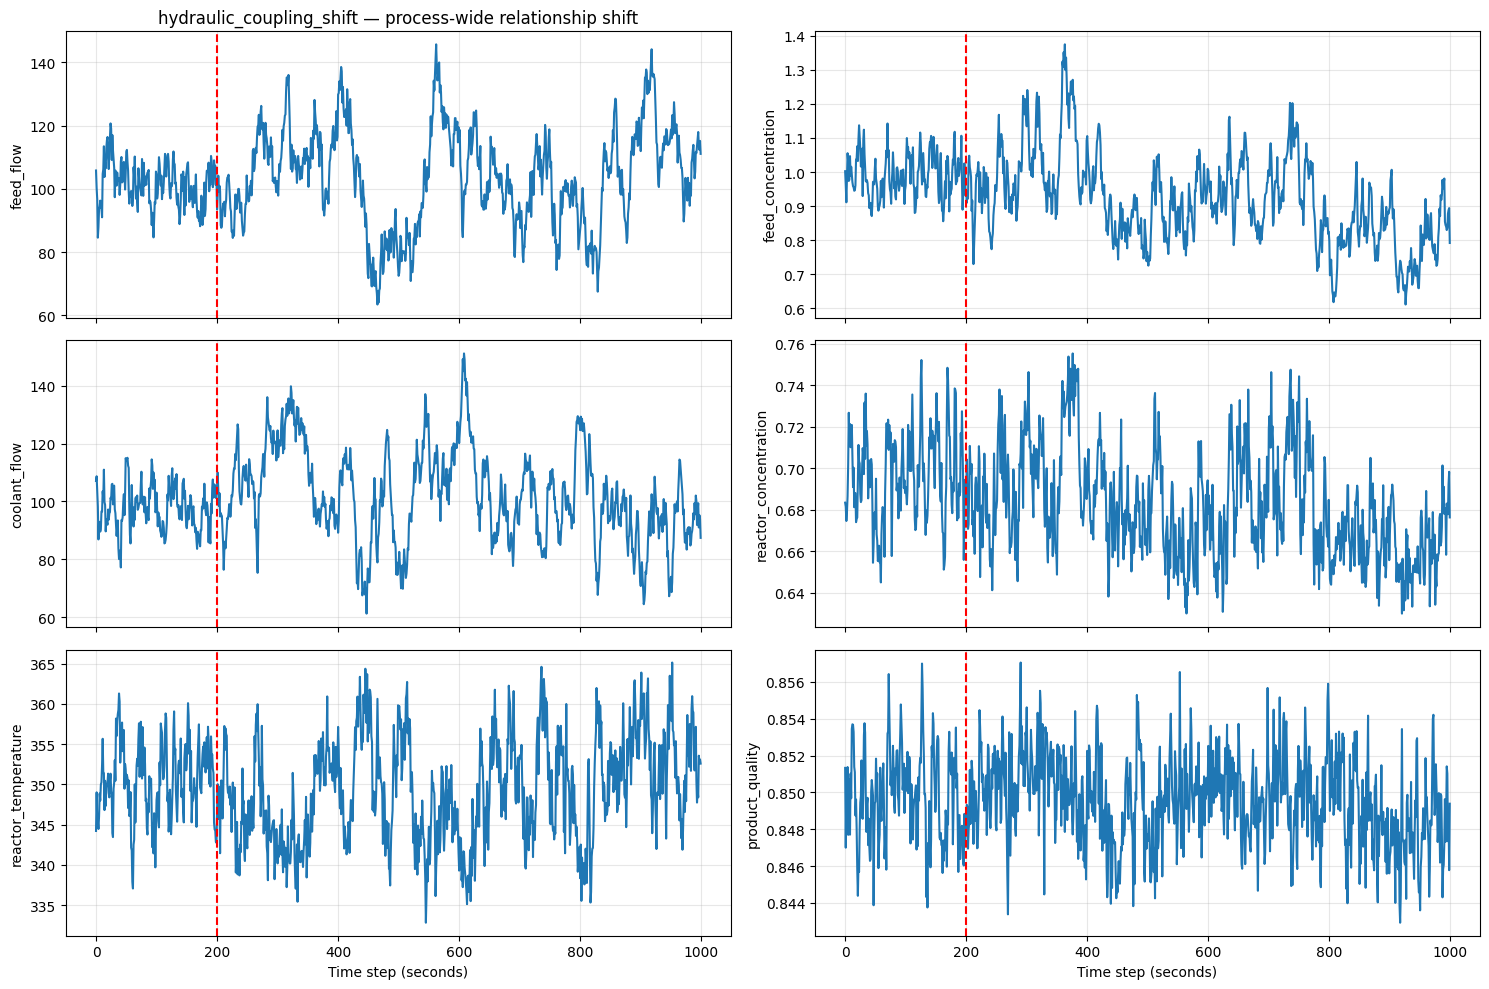

,run_id,source,target,lag_steps,coefficient_before,coefficient_after,change_fraction,requested_change_fraction
2,run_hydraulic_coupling_shift_00500,coolant_flow,coolant_flow,1,0.75,0.950000,0.266667,0.494356
1,run_hydraulic_coupling_shift_00500,feed_concentration,feed_concentration,1,0.70,0.950000,0.357143,0.378620
0,run_hydraulic_coupling_shift_00500,feed_flow,feed_flow,1,0.75,0.950000,0.266667,0.451788
11,run_hydraulic_coupling_shift_00500,product_quality,product_quality,1,0.55,0.339130,0.383401,0.383401
12,run_hydraulic_coupling_shift_00500,reactor_concentration,product_quality,1,0.22,0.129630,0.410773,0.410773
13,run_hydraulic_coupling_shift_00500,reactor_temperature,product_quality,2,-0.16,-0.220374,0.377335,0.377335
4,run_hydraulic_coupling_shift_00500,feed_concentration,reactor_concentration,1,0.22,0.311146,0.414299,0.414299
5,run_hydraulic_coupling_shift_00500,feed_flow,reactor_concentration,1,-0.12,-0.063968,0.466930,0.466930
3,run_hydraulic_coupling_shift_00500,reactor_concentration,reactor_concentration,1,0.62,0.340067,0.451505,0.451505
6,run_hydraulic_coupling_shift_00500,reactor_temperature,reactor_concentration,1,0.08,0.113788,0.422349,0.422349


In [5]:
fault_run = runs.loc[runs["fault_type"] != "healthy"].iloc[0]
trajectory = traces.loc[traces["run_id"] == fault_run["run_id"]]

fig, axes = plt.subplots(3, 2, figsize=(15, 10), sharex=True)
for ax, signal in zip(
    axes.flat,
    VARIABLE_NAMES,
):
    ax.plot(trajectory["time_step"], trajectory[signal])
    ax.axvline(fault_run["fault_start_step"], color="red", linestyle="--")
    ax.set_ylabel(signal)
    ax.grid(True, alpha=0.3)
axes[0, 0].set_title(
    f"{fault_run['fault_type']} — process-wide relationship shift"
)
axes[-1, 0].set_xlabel("Time step (seconds)")
axes[-1, 1].set_xlabel("Time step (seconds)")
plt.tight_layout()
plt.show()

display(
    fault_coefficients.loc[
        fault_coefficients["run_id"] == fault_run["run_id"]
    ].sort_values(["target", "source", "lag_steps"])
)

## Ground-truth causal graph

`causal_graph.csv` gives the baseline topology and coefficients from the SEM validated with CausalAI. Every fault preserves this topology but changes the coefficient on every edge after its onset; `fault_coefficients.csv` records each run's baseline coefficient, randomized change magnitude, and post-onset coefficient. Fault profiles determine the direction of each edge change, while random magnitudes make instances distinct. Since all edges point from past to present, the time-unrolled graph is acyclic.

In [6]:
display(causal_graph.sort_values(["target", "source", "lag_steps"]).reset_index(drop=True))

,source,target,lag_steps,coefficient,function,mechanism
0,coolant_flow,coolant_flow,1,0.75,identity,input_persistence
1,feed_concentration,feed_concentration,1,0.70,identity,input_persistence
2,feed_flow,feed_flow,1,0.75,identity,input_persistence
3,product_quality,product_quality,1,0.55,identity,state_persistence
4,reactor_concentration,product_quality,1,0.22,tanh,conversion
5,reactor_temperature,product_quality,2,-0.16,tanh,temperature_sensitivity
6,feed_concentration,reactor_concentration,1,0.22,tanh,feed_mixing
7,feed_flow,reactor_concentration,1,-0.12,tanh,hydraulic_residence
8,reactor_concentration,reactor_concentration,1,0.62,identity,state_persistence
9,reactor_temperature,reactor_concentration,1,0.08,tanh,reaction_kinetics


## Files written

- `traces.parquet`: continuous sensor/process values, run ID, time step, anomaly label, and split.
- `runs.csv`: fault profile, exact onset step, random seed, and split.
- `causal_graph.csv`: SEM-derived graph edges and their nonlinear mechanisms.
- `fault_coefficients.csv`: per-fault-run coefficient values before and after the change.
- `metadata.json`: Salesforce CausalAI version, fixed sampling interval, fault profiles, and generator assumptions.

Increase `RUNS_PER_CLASS` for more independent trajectories or `SAMPLES_PER_RUN` for longer runs. Splits remain grouped by run.